# Istanbul earthquake scenario: neighbourhood-level analysis

This notebook works with the earthquake scenario results published by the Istanbul
Metropolitan Municipality (IMM / İBB) for 959 neighbourhoods (mahalle) in 39 districts.

The numbers in the table are **outputs of the municipality's scenario model** (estimated
building damage, casualties and needs for one hypothetical earthquake). They are not
observed events. The models below therefore measure how well the published casualty
estimates can be reproduced from the published damage estimates; they do not predict
what would happen in a real earthquake.

Steps:
1. Load and clean the table.
2. Join neighbourhoods to boundary polygons from OpenStreetMap.
3. Build a weighted building-damage index, test its sensitivity to the weights, rank
   neighbourhoods and districts.
4. Cross-validate models of deaths + serious injuries from the four damage counts.
5. Save static figures (`figures/`), tables (`results/`) and an interactive map (`maps/`).

The same steps run without Jupyter via `python scripts/build_outputs.py`.

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from eqscenario import data, geo, index, modeling, plots

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
FIG, RES = ROOT / "figures", ROOT / "results"
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

## 1. Data

The CSV is Windows-1254 (Turkish) encoded. Reading it as `cp1254` gives correct Turkish
letters directly. `EYÜP` is renamed to `EYÜPSULTAN` (renamed in 2017) so it matches the
boundary data.

In [2]:
df = data.load_scenario()
print(df.shape, "rows x columns;", df["district"].nunique(), "districts")
df[["district", "neighbourhood"] + data.DAMAGE_COLS + ["can_kaybi_sayisi", "agir_yarali_sayisi"]].head()

(959, 19) rows x columns; 39 districts


,district,neighbourhood,cok_agir_hasarli_bina_sayisi,agir_hasarli_bina_sayisi,orta_hasarli_bina_sayisi,hafif_hasarli_bina_sayisi,can_kaybi_sayisi,agir_yarali_sayisi
0,Adalar,Burgazada,54,99,256,241,8,6
1,Adalar,Heybeliada,101,175,423,393,25,21
2,Adalar,Kınalıada,53,97,287,302,5,3
3,Adalar,Maden,104,192,483,484,22,18
4,Adalar,Nizam,101,180,445,422,16,13


In [3]:
totals = df[data.DAMAGE_COLS + data.CASUALTY_COLS + ["gecici_barinma"]].sum()
totals.rename("Istanbul total").to_frame()

,Istanbul total
cok_agir_hasarli_bina_sayisi,13496
agir_hasarli_bina_sayisi,34334
orta_hasarli_bina_sayisi,146512
hafif_hasarli_bina_sayisi,301524
can_kaybi_sayisi,14145
agir_yarali_sayisi,8090
hastanede_tedavi_sayisi,39636
hafif_yarali_sayisi,75240
gecici_barinma,835918


## 2. Neighbourhood polygons

The polygons come from OpenStreetMap (compiled through the Nominatim API in the
`sahircansurmeli/istanbul-geojson` repository, pinned to a commit). They are downloaded on
first run into `data/external/` and are not committed. Licence: ODbL 1.0,
(c) OpenStreetMap contributors.

Each polygon is assigned to the district whose polygon contains its representative point,
then matched on normalised (district, neighbourhood) names, with a short alias list for
spelling differences and renames.

In [4]:
districts = geo.load_districts()
polys = geo.load_neighbourhood_polygons()
nb = geo.attach_polygons(index.add_index(df), polys)
print("usable district-assigned polygons:", len(polys))
print("scenario rows with a polygon:", nb.geometry.notna().sum(), "of", len(nb))
nb.loc[nb.geometry.isna(), ["district", "neighbourhood"]]

usable district-assigned polygons: 967
scenario rows with a polygon: 953 of 959


,district,neighbourhood
95,Bahçelievler,Fevzi Çakmak
96,Bahçelievler,Hürriyet
97,Bahçelievler,Kocasinan Merkez
228,Beyoğlu,Evliya Çelebi
236,Beyoğlu,İstiklal
726,Silivri,Gümüşyaka


## 3. Weighted building-damage index

The table gives four damage levels: very heavy (çok ağır), heavy (ağır), moderate (orta)
and light (hafif). The index prioritises severe damage using analyst-chosen weights.
They are not official IMM weights or calibrated replacement-cost ratios:

| level | weight |
| --- | --- |
| very heavy | 1.00 |
| heavy | 0.50 |
| moderate | 0.10 |
| light | 0.02 |

`damage_index = 1.0*very_heavy + 0.5*heavy + 0.1*moderate + 0.02*light`, i.e. the number of
very-heavy-damage-equivalent buildings, a ranking proxy rather than a literal loss estimate.
`severity` = index / damaged buildings is the average severity weight among damaged buildings.

The index measures physical damage. The table has no building stock or population, so it
is not normalised by exposure.

In [5]:
sens = index.sensitivity(nb)
sens.round(3).to_csv(RES / "weight_sensitivity.csv", index=False)
sens.round(3)

,scheme,"weights (vh, h, m, l)",spearman_vs_main,top50_overlap_with_main,spearman_vs_deaths_serious
0,severity weights (main),"1, 0.5, 0.1, 0.02",1.000,1.00,0.839
1,linear 4-3-2-1,"4, 3, 2, 1",0.981,0.78,0.802
2,equal (count),"1, 1, 1, 1",0.958,0.74,0.779
3,steep 1-0.25-0.05-0.01,"1, 0.25, 0.05, 0.01",0.998,0.96,0.850
4,collapse only,"1, 0, 0, 0",0.959,0.78,0.874


The overall ranking is stable across weighting schemes (Spearman rank correlation with the
main scheme between 0.958 and 0.998). The top-50 list is more sensitive: 74 to 96 percent of
it is shared with the main scheme. The "collapse only" scheme tracks casualties most closely,
which is expected because the scenario casualties depend mostly on very heavy damage (see
section 4).

In [6]:
cols = ["rank", "district", "neighbourhood", "damage_index", "severity", "damaged_buildings",
        "cok_agir_hasarli_bina_sayisi", "deaths_serious"]
nb_table = nb.sort_values("rank")[cols + ["mahalle_koy_uavt", "can_kaybi_sayisi",
                                          "gecici_barinma"]].assign(has_polygon=nb.geometry.notna())
nb_table.round(3).to_csv(RES / "neighbourhood_index.csv", index=False)
nb_table[cols].head(15).round(2)

,rank,district,neighbourhood,damage_index,severity,damaged_buildings,cok_agir_hasarli_bina_sayisi,deaths_serious
114,1,Bakırköy,Yeşilköy,438.02,0.24,1828,201,253
69,2,Avcılar,Yeşilkent,398.04,0.09,4366,36,63
588,3,Küçükçekmece,Kanarya,337.90,0.14,2363,116,235
586,4,Küçükçekmece,İnönü,336.88,0.13,2661,95,226
102,5,Bahçelievler,Zafer,314.02,0.12,2596,101,326
875,6,Tuzla,Şifa,303.96,0.17,1747,103,131
112,7,Bakırköy,Şenlikköy,296.06,0.21,1425,110,190
133,7,Bayrampaşa,Muratpaşa,296.06,0.15,1915,116,156
581,9,Küçükçekmece,Cumhuriyet,292.16,0.17,1747,109,237
438,10,Fatih,Ayvansaray,291.76,0.17,1741,111,103


In [7]:
dist = index.district_index(nb)
dist.round(3).to_csv(RES / "district_index.csv", index=False)
dist.head(10).round(2)

,district,damage_index,damaged_buildings,deaths_serious,can_kaybi_sayisi,gecici_barinma,severity,rank
0,Fatih,5141.06,31286,2469,1484,46784,0.16,1
1,Küçükçekmece,3721.78,26633,2440,1515,72774,0.14,2
2,Bağcılar,2816.54,26019,1831,1179,59513,0.11,3
3,Esenyurt,2531.54,24914,1546,1003,67410,0.10,4
4,Bahçelievler,2301.52,17640,2512,1633,61199,0.13,5
5,Silivri,2252.94,21303,85,58,13481,0.11,6
6,Büyükçekmece,2106.04,18063,442,288,24298,0.12,7
7,Bakırköy,1853.18,9421,1627,1046,28910,0.20,8
8,Tuzla,1826.78,15365,437,268,21417,0.12,9
9,Bayrampaşa,1759.20,13270,860,520,23064,0.13,10


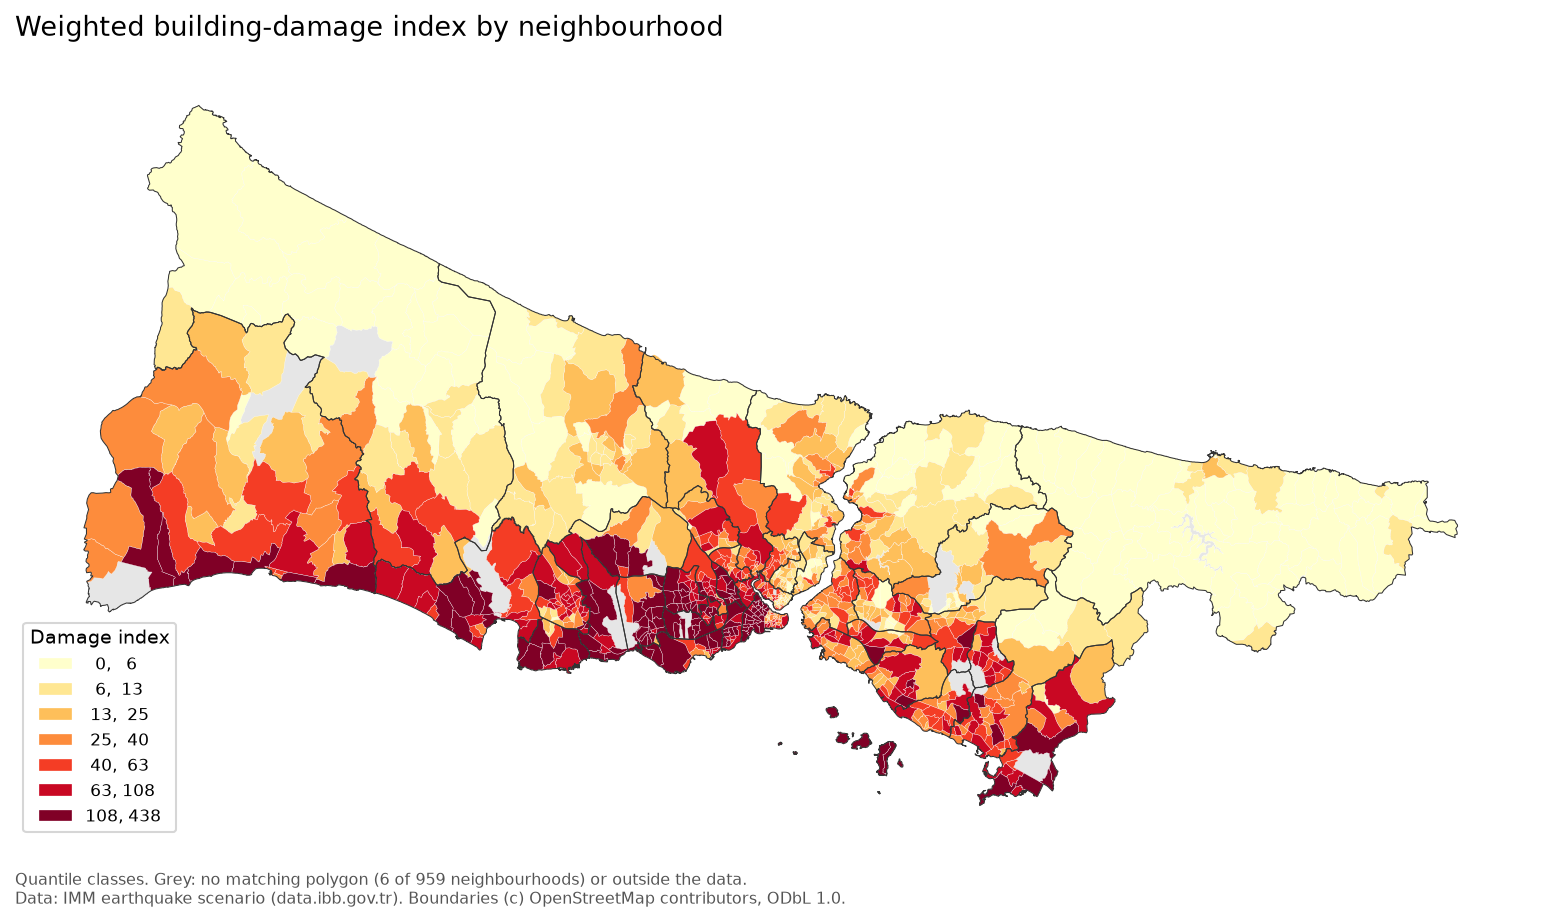

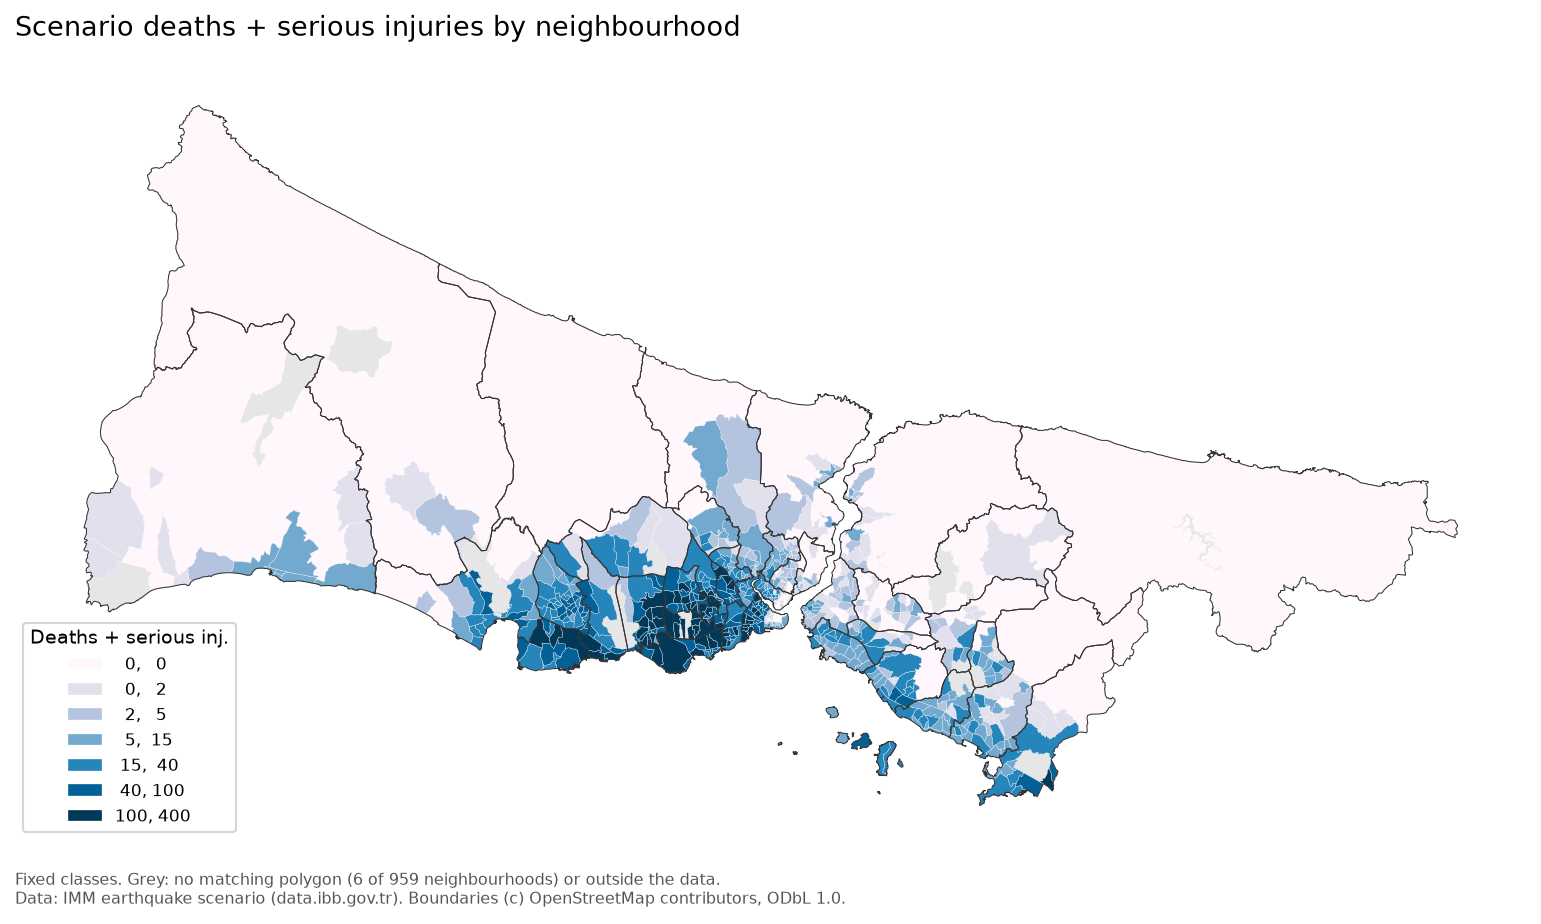

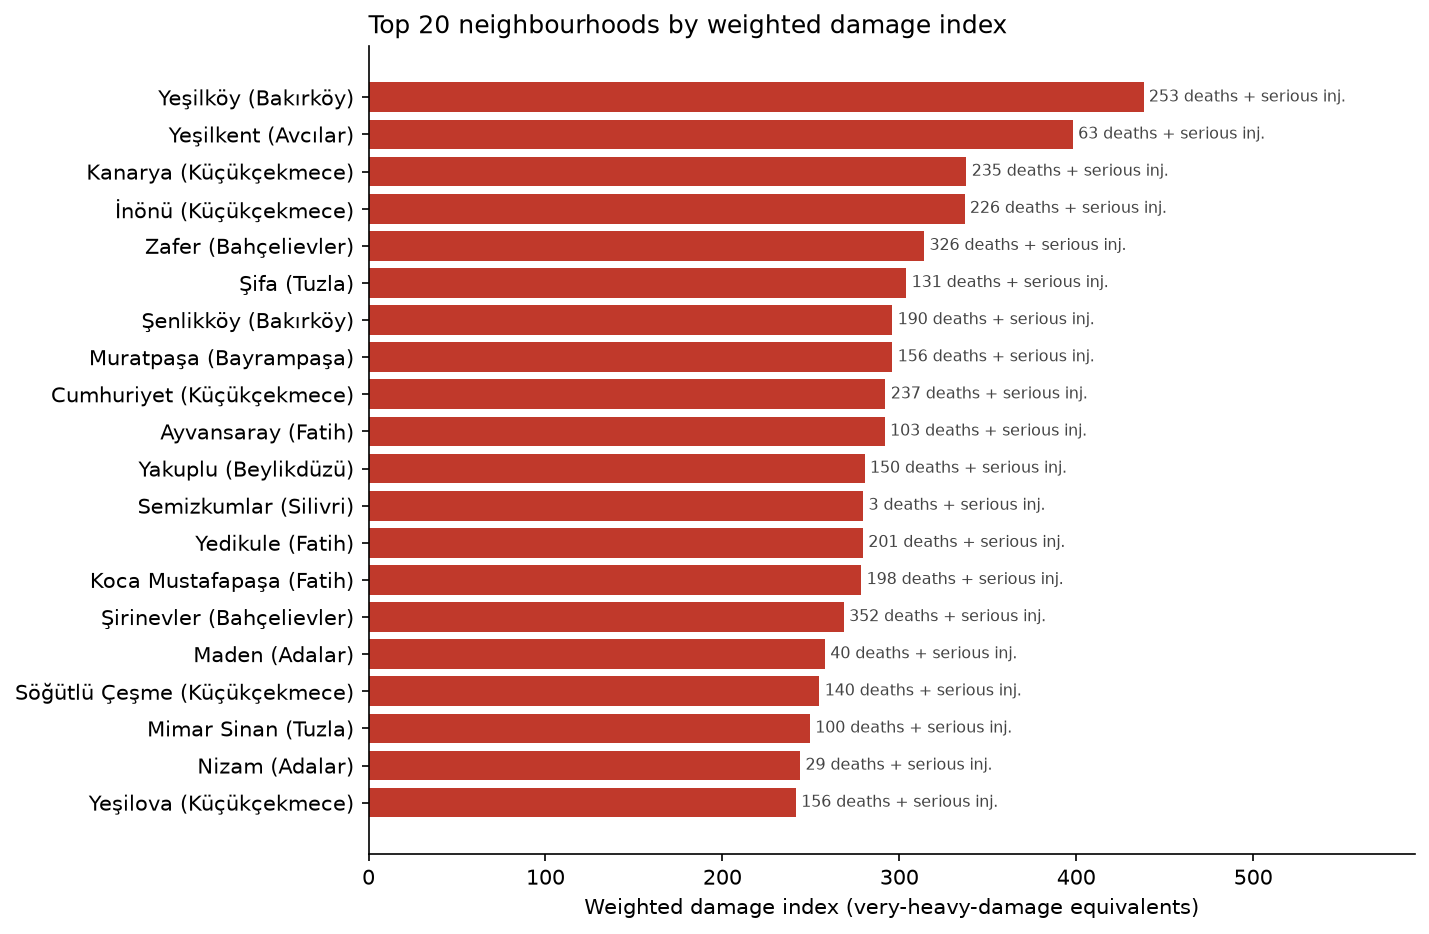

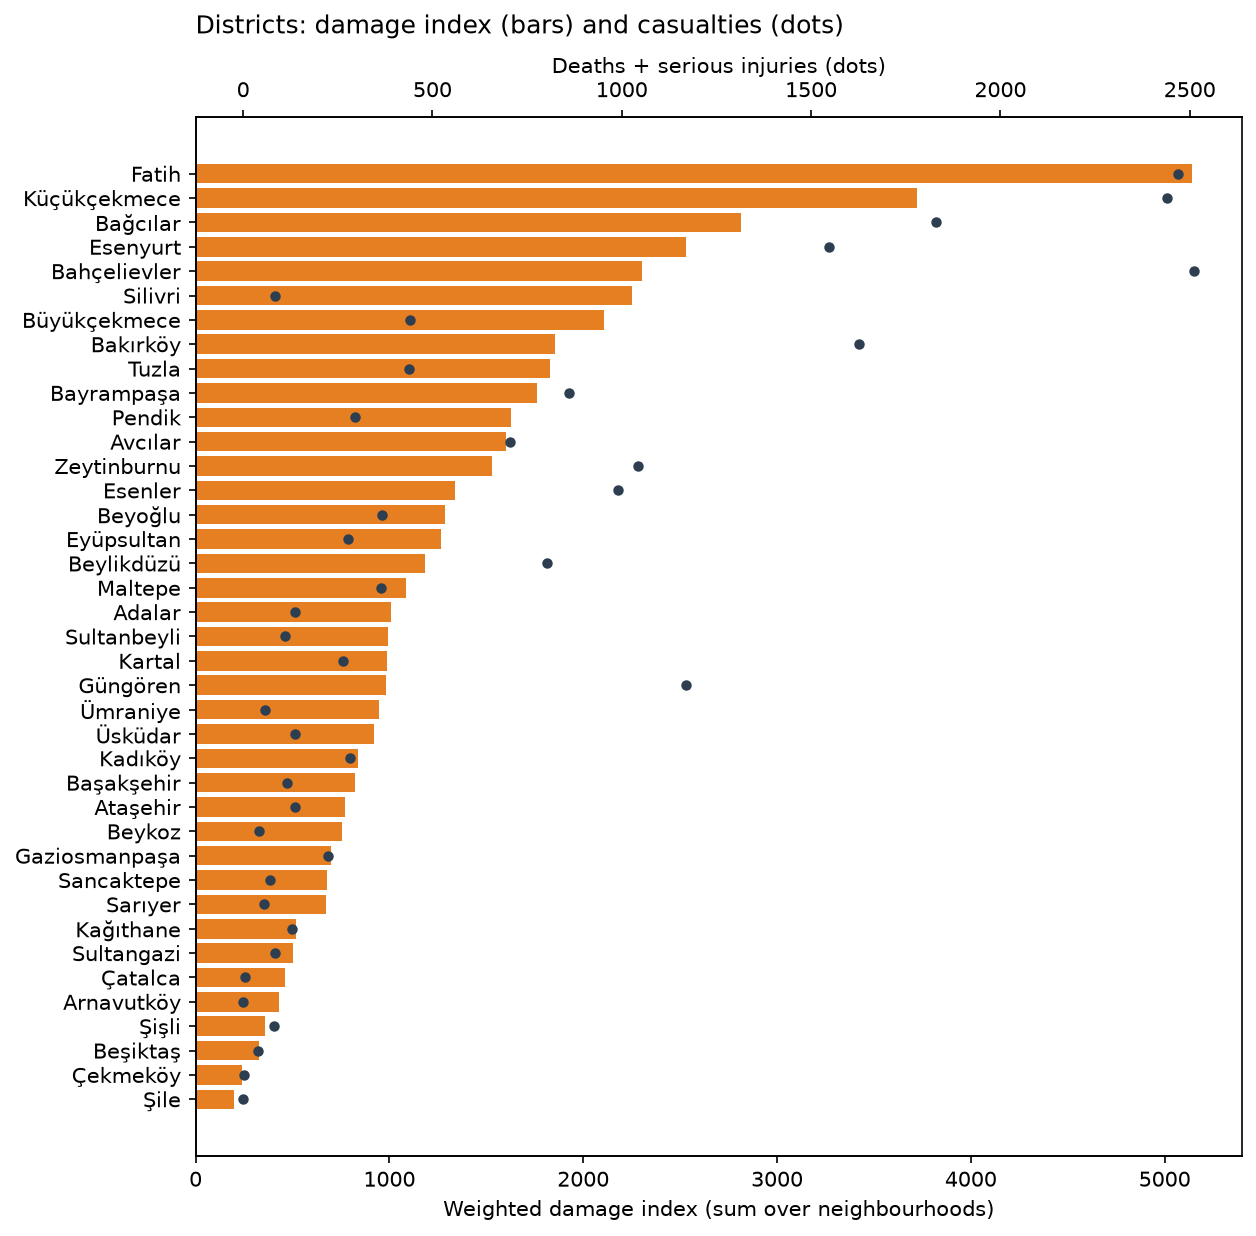

In [8]:
plots.choropleth(nb, districts, "damage_index", "Weighted building-damage index by neighbourhood",
                 "Damage index", FIG / "damage_index_map.png")
plots.choropleth(nb, districts, "deaths_serious", "Scenario deaths + serious injuries by neighbourhood",
                 "Deaths + serious inj.", FIG / "casualties_map.png", cmap="PuBu",
                 bins=[0, 2, 5, 15, 40, 100, 400])
plots.top_neighbourhoods_bar(nb, FIG / "top_neighbourhoods.png")
plots.district_bar(districts.merge(dist, on="district", how="left"), FIG / "district_index.png")
for name in ["damage_index_map", "casualties_map", "top_neighbourhoods", "district_index"]:
    display(Image(filename=str(FIG / f"{name}.png"), width=850))

## 4. Models: deaths + serious injuries from damage counts

Target: `can_kaybi_sayisi + agir_yarali_sayisi` per neighbourhood. Features: the four damage
counts. Models:

- ratio baseline: casualties proportional to very heavily damaged buildings (no intercept);
- linear regression on the four counts;
- Poisson GLM (log link) on `log1p` of the counts, which fits count data and allows a
  power-law relation;
- histogram gradient boosting with Poisson loss.

Two 5-fold schemes: random folds, and folds grouped by district (all neighbourhoods of a
district are in the same fold). The grouped scheme tests transfer to districts the model has
not seen; neighbourhoods of one district share building stock and distance to the fault, so
random folds are optimistic. Poisson deviance is computed with predictions floored at 0.001
(linear regression can predict negative values).

In [9]:
folds, summary, oof = modeling.cross_validate(nb)
folds.round(4).to_csv(RES / "cv_folds.csv", index=False)
summary.round(3).to_csv(RES / "cv_summary.csv", index=False)
summary.round(3)

,split,model,r2_mean,r2_std,mae_mean,mae_std,poisson_dev_mean,poisson_dev_std
0,random 5-fold,Ratio baseline (very heavy only),0.711,0.040,11.698,2.174,10.921,2.037
1,random 5-fold,Linear regression,0.747,0.035,12.157,1.530,17.290,5.066
2,random 5-fold,Poisson GLM (log1p features),0.763,0.060,10.219,1.705,9.416,1.597
3,random 5-fold,Gradient boosting (Poisson loss),0.691,0.040,11.230,2.134,10.869,2.436
4,grouped by district 5-fold,Ratio baseline (very heavy only),0.587,0.397,11.666,3.424,11.087,4.466
5,grouped by district 5-fold,Linear regression,0.646,0.295,12.398,2.961,21.737,16.081
6,grouped by district 5-fold,Poisson GLM (log1p features),0.652,0.253,10.682,3.530,10.055,3.884
7,grouped by district 5-fold,Gradient boosting (Poisson loss),0.553,0.319,12.227,4.875,12.819,5.338


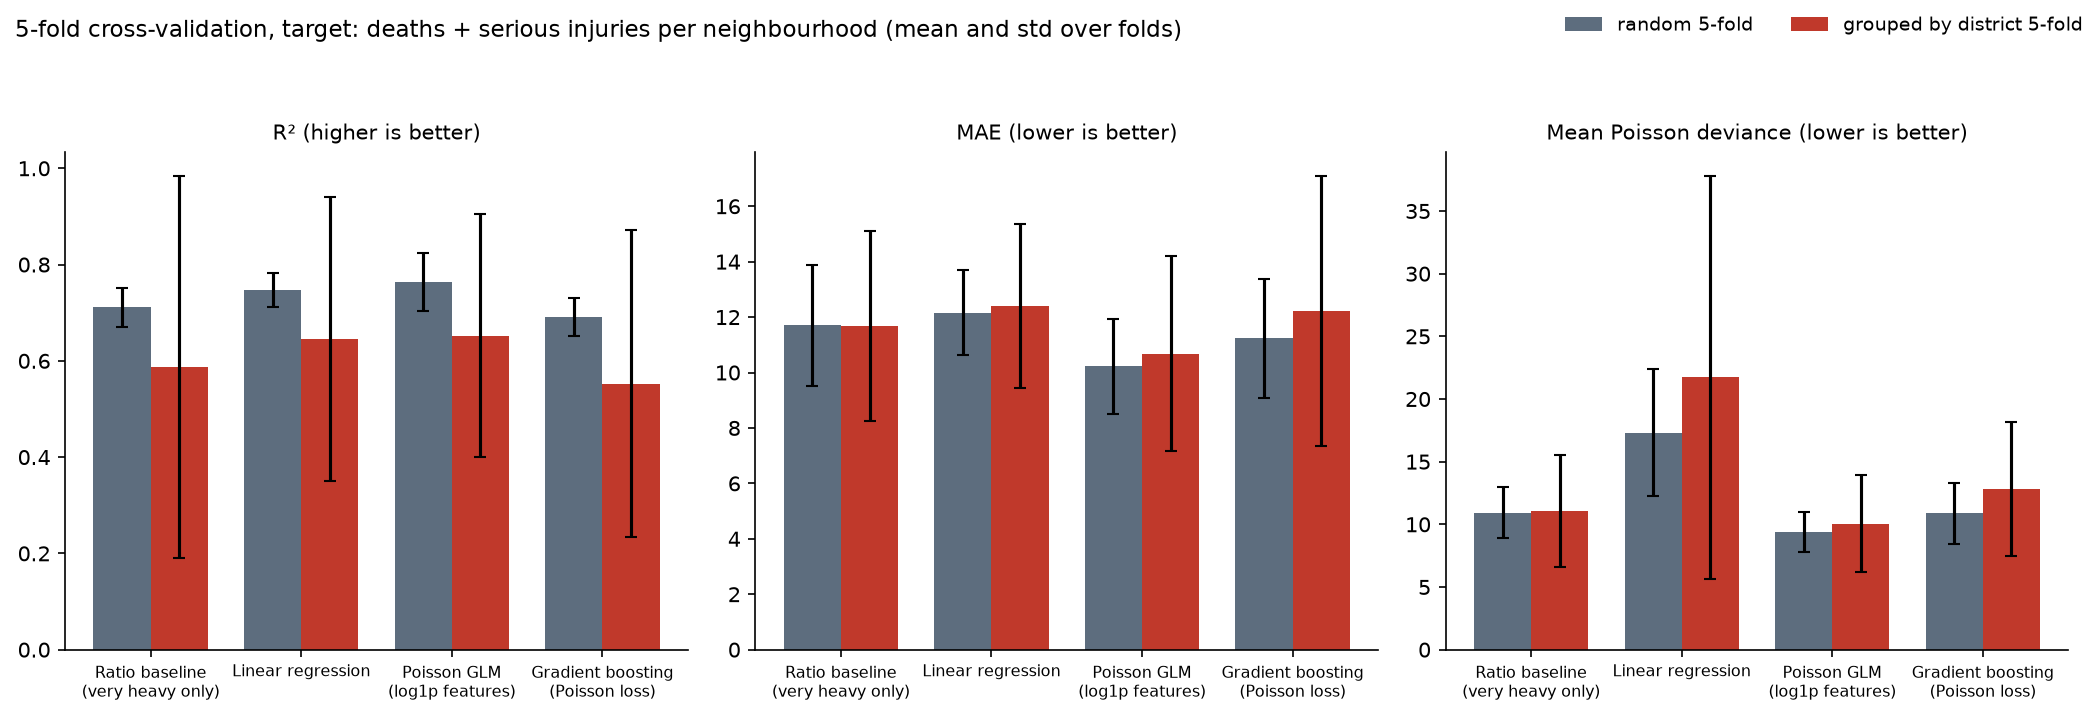

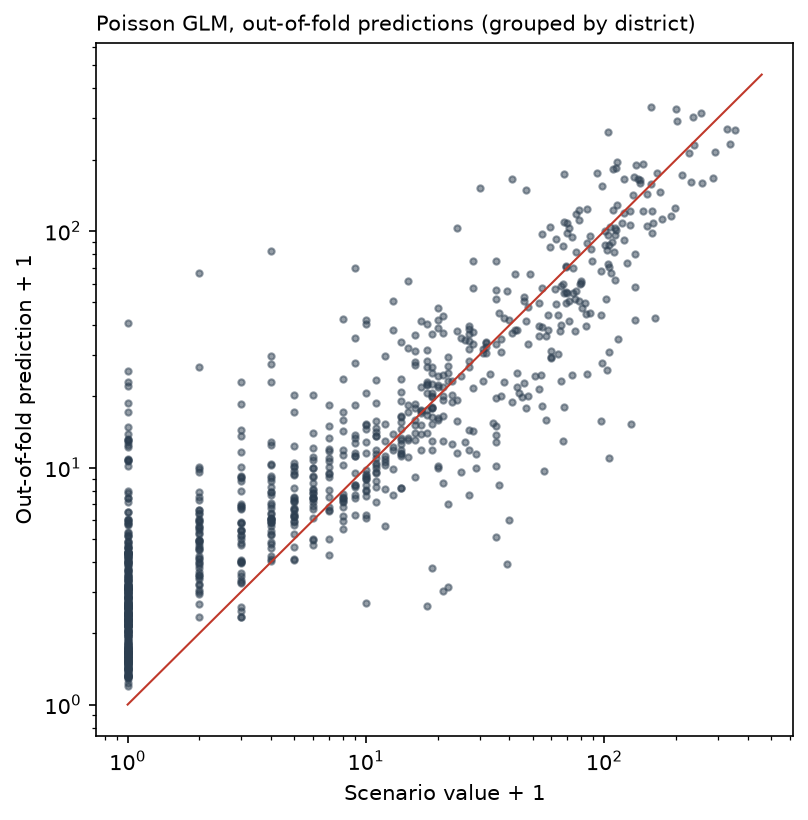

In [10]:
plots.model_comparison(summary, FIG / "model_comparison.png")
best = ("grouped by district 5-fold", "Poisson GLM (log1p features)")
plots.oof_scatter(nb[modeling.TARGET].to_numpy(), oof[best],
                  "Poisson GLM, out-of-fold predictions (grouped by district)",
                  FIG / "oof_poisson_glm.png")
display(Image(filename=str(FIG / "model_comparison.png"), width=950))
display(Image(filename=str(FIG / "oof_poisson_glm.png"), width=450))

### Which damage level drives casualties?

1. Casualties per building at each level from a non-negative linear fit without intercept.
2. Grouped-CV R² of a Poisson GLM that sees only one damage level.

In [11]:
rates = modeling.per_building_rates(nb)
rates.round(4).to_csv(RES / "per_building_rates.csv", index=False)
rates.round(4)

,damage_level,buildings_total,casualties_per_building,share_of_fitted_casualties
0,very heavy,13496,1.6700,0.9328
1,heavy,34334,0.0000,0.0000
2,moderate,146512,0.0000,0.0000
3,light,301524,0.0054,0.0672


In [12]:
single = modeling.single_feature_cv(nb)
single.round(3).to_csv(RES / "single_feature_cv.csv", index=False)
single.round(3)

,damage_level,grouped_cv_r2_mean,grouped_cv_r2_std,pooled_oof_r2,spearman_with_target
0,very heavy,0.499,0.494,0.655,0.874
1,heavy,0.339,0.626,0.505,0.831
2,moderate,0.187,0.513,0.323,0.787
3,light,0.138,0.266,0.256,0.726


In [13]:
vh = nb["cok_agir_hasarli_bina_sayisi"].sum()
print(f"deaths per very heavily damaged building: {nb['can_kaybi_sayisi'].sum() / vh:.2f}")
print(f"deaths + serious injuries per very heavily damaged building: {nb['deaths_serious'].sum() / vh:.2f}")
print("correlation between damage levels (Spearman):")
nb[data.DAMAGE_COLS].corr(method="spearman").round(2)

deaths per very heavily damaged building: 1.05
deaths + serious injuries per very heavily damaged building: 1.65
correlation between damage levels (Spearman):


,cok_agir_hasarli_bina_sayisi,agir_hasarli_bina_sayisi,orta_hasarli_bina_sayisi,hafif_hasarli_bina_sayisi
cok_agir_hasarli_bina_sayisi,1.00,0.97,0.90,0.77
agir_hasarli_bina_sayisi,0.97,1.00,0.97,0.86
orta_hasarli_bina_sayisi,0.90,0.97,1.00,0.95
hafif_hasarli_bina_sayisi,0.77,0.86,0.95,1.00


The Poisson GLM has the lowest MAE and deviance in both split schemes. Its mean R² falls
from 0.763 with random folds to 0.652 with district-held-out folds; the grouped-fold standard
deviation is 0.253, so performance differs substantially across district groups. These are
fixed model comparisons, not nested hyperparameter tuning or an external validation set.

Very heavy damage is the strongest individual feature, but its mean grouped-fold R² of
0.499 is below the four-feature GLM's 0.652. The single-feature table also reports pooled
out-of-fold R², which must not be compared with mean fold R². In the descriptive non-negative
fit, very heavy damage accounts for 93 percent of fitted deaths + serious injuries. The
features are correlated, so zero coefficients for heavy and moderate damage do not establish
that those damage levels cause no casualties.

## 5. Interactive map

Saved to `maps/istanbul_damage_map.html` (not displayed inline to keep the notebook small).

In [14]:
path = plots.interactive_map(nb, districts, ROOT / "maps" / "istanbul_damage_map.html")
print(path.relative_to(ROOT).as_posix(), f"{path.stat().st_size / 1e6:.1f} MB")

maps/istanbul_damage_map.html 3.2 MB
